# Contrast Limited Adaptive Histogram Equalization
## Ecualización adaptativa del histograma con limitación de contraste

### Samira Sofia Rodriguez Peregrino

##### Este proyecto aplica la técnica CLAHE para mejorar el contraste en imágenes de retinas oculares. Su uso permite resaltar detalles y estructuras que no se observan con claridad en la imagen original, facilitando su análisis visual en el laboratorio.

### Objetivo
##### Documentar y organizar un repositorio de procesamiento de imágenes de retinas oculares mediante CLAHE para mejorar el contraste y facilitar su análisis visual.

### Concepto
##### Es una técnica de preprocesamiento de imágenes que sirve para mejorar el contraste local de una imagen, haciendo que detalles poco visibles se noten más, sin amplificar demasiado el ruido. A diferencia de una ecualización de histograma normal (HE), CLAHE trabaja por regiones pequeñas de la imagen y además limita cuánto puede aumentar el contraste en zonas homogéneas, para evitar que el ruido se dispare
##### CLAHE es un algoritmo de mejora de imagen que aumenta el contraste local para resaltar detalles pequeños sin aumentar demasiado el ruido

### ¿Cómo funciona?
##### 1. Divide la imagen en pequeños bloques, ya que trata a la imagen en zonas pequeñas y no completa.
##### 2. Hace una ecualización local del histograma en cada bloque, significa que redistribuye los niveles de intensidad dentro de cada región para que los contrastes locales se vean mejor.
##### 3. Aplica un límite de contraste (clip limit), por si una zona tiene demasiados píxeles con intensidades muy parecidas.
##### 4. Interpola entre bloques, para que no se noten bordes artificales entre una región y otra, une suavemente los resultados. 
##### CLAHE mejora detalles locales de la imagen, pero controlando que el realce no se vuelva exagerado ni ruidoso.

### ¿Para qué sirve?
##### En el caso de medicina computacionasl se usa porque muchas imágenes médicas tienen problemas con el bajo contraste, una iluminación no uniforme, detalles anatómicos sutiles difíciles de ver, estructuras pequeñas escondidas en el fondo o ruido que puede confundir al modelo. 
##### Por lo que, CLAHE sirve para hacer más visibles las estructuras relevantes como vasos sanguíneos, lesiones pequeñas, bordes de tumores, entre otros.

### ¿Cómo se utiliza en medicina computacional?
##### En medicina computacional se usa en imágenes médicas, si esa imagen se ve con poco contraste o los detalles no se distinguen bien se aplica CLAHE para hacer más visibles los detalles pequeños, resalta estructuras y mejroa la calidad visual de la imagen. 
##### En medicina computacional, CLAHE se usa para mejorar imágenes médicas antes de que una computadora las analice

In [1]:
from PIL import Image # Para abrir, leer, manipular y guardar imagenes
import matplotlib.pyplot as plt
import numpy as np
import os # para trabajar con carpetas, rutas y archivos del sistema
import cv2

In [11]:
# Ruta de la carpeta de imágenes
carpeta_imagenes = 'C:/Users/samir/OneDrive/Escritorio/Servicio/Bit-cora-de-laboratorio-Samira/tareas/Peorcitas'


# Filtrar solo archivos de imagen (puedes ajustar según el formato que uses: .jpg, .png, etc.)
formatos_validos = (".jpg", ".png", ".jpeg")

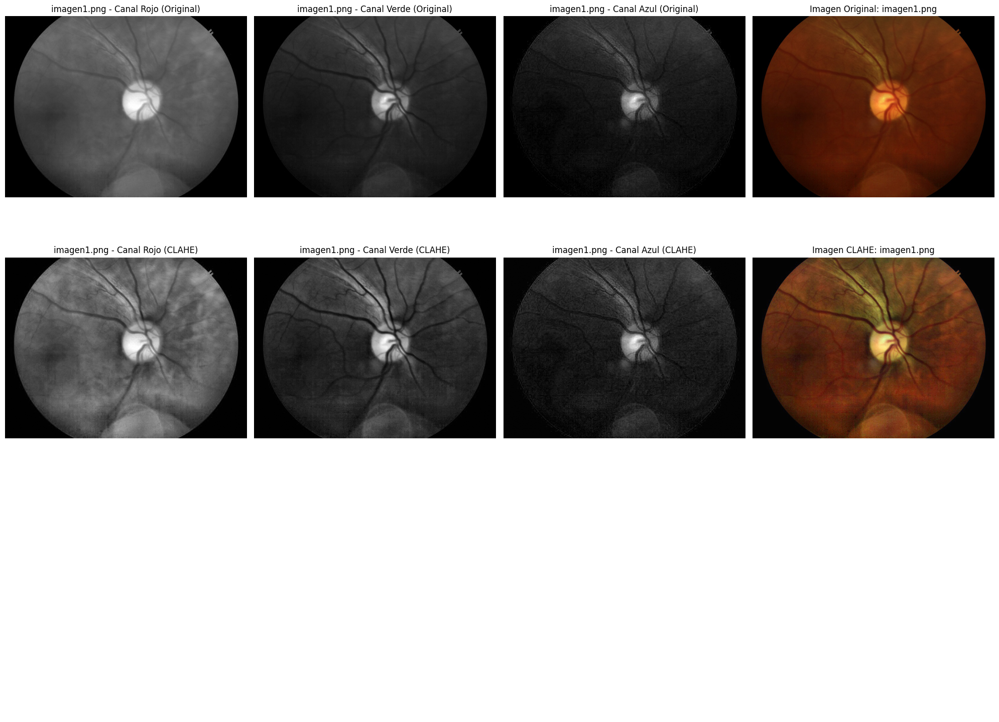

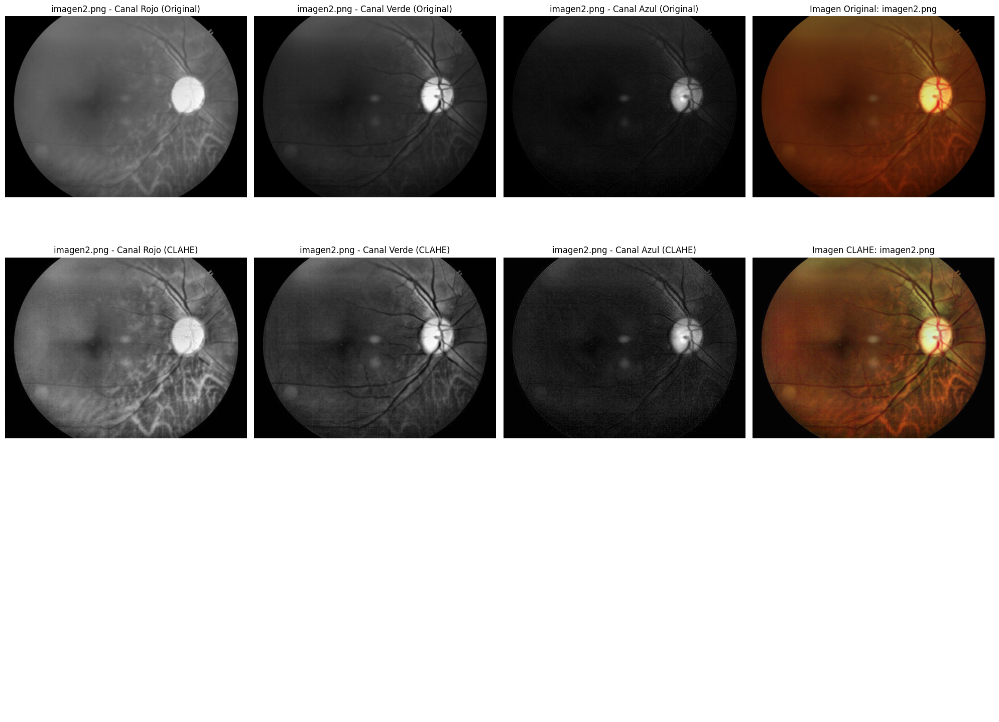

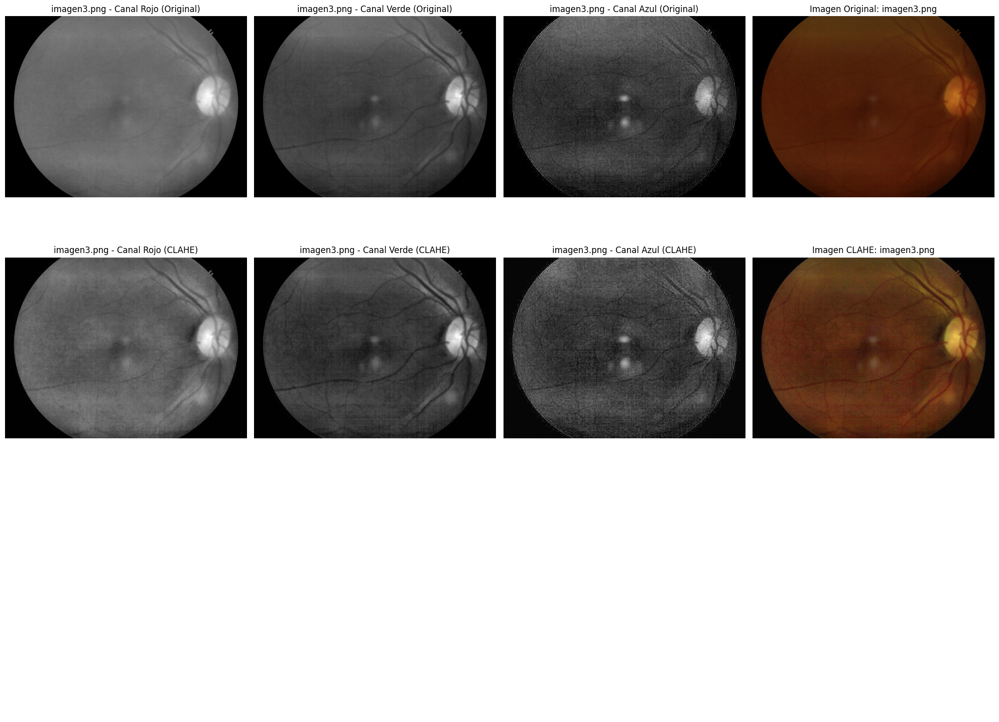

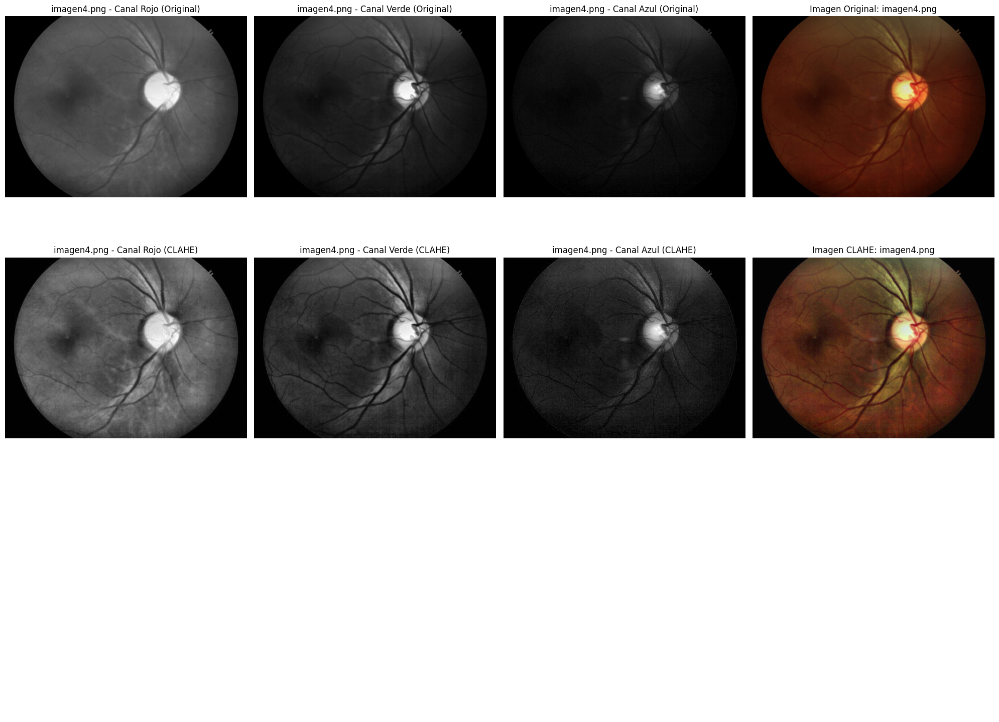

In [10]:
# Crear un objeto CLAHE, crea herramienta que va a aplicar
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)) # cliplimit cuanto contraste se puede aumentar
 # TildeG le dice en cuantas regiones pequeñas va a dividir la imagen

# Iterar sobre todas las imágenes de la carpeta
for archivo_imagen in os.listdir(carpeta_imagenes): # va leyendo imagen por imagen automáticamente de una lista de archivos
    if archivo_imagen.endswith(formatos_validos): # revisa si el archivo termina en una extensión válida
        ruta_imagen = os.path.join(carpeta_imagenes, archivo_imagen) # crea la ruta a la imagen
        # Cargar la imagen en color
        imagen = cv2.imread(ruta_imagen) # abre la imagen y la carga en memoria como una matriz numérica
        # Separar los canales RGB, extrae cada canal de color por separado
        canal_rojo = imagen[:, :, 2]  # OpenCV carga en BGR, así que el rojo está en el índice 2
        canal_verde = imagen[:, :, 1]  # Verde en el índice 1
        canal_azul = imagen[:, :, 0]   # Azul en el índice 0
        # Aplicar CLAHE a cada canal, toma cada canal por separado y le mejora el contraste usando CLAHE
        canal_rojo_clahe = clahe.apply(canal_rojo)
        canal_verde_clahe = clahe.apply(canal_verde)
        canal_azul_clahe = clahe.apply(canal_azul)
        
        
        # Combinar los canales CLAHE
        clahe_imagen = cv2.merge((canal_azul_clahe, canal_verde_clahe, canal_rojo_clahe))  # OpenCV usa BGR
        # después de mejorar cada canal por separado, los vuelve a unir para reconstruir la imagen completa

        # Crear un gráfico para mostrar los canales y las imágenes
        fig, axs = plt.subplots(3, 4, figsize=(20, 15))

        # Canales originales en escala de grises
        axs[0, 0].imshow(canal_rojo, cmap='gray')
        axs[0, 0].set_title(f"{archivo_imagen} - Canal Rojo (Original)")
        axs[0, 0].axis('off')

        axs[0, 1].imshow(canal_verde, cmap='gray')
        axs[0, 1].set_title(f"{archivo_imagen} - Canal Verde (Original)")
        axs[0, 1].axis('off')

        axs[0, 2].imshow(canal_azul, cmap='gray')
        axs[0, 2].set_title(f"{archivo_imagen} - Canal Azul (Original)")
        axs[0, 2].axis('off')

        # Imagen original
        axs[0, 3].imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
        axs[0, 3].set_title(f'Imagen Original: {archivo_imagen}')
        axs[0, 3].axis('off')

        # Canales CLAHE en escala de grises
        axs[1, 0].imshow(canal_rojo_clahe, cmap='gray')
        axs[1, 0].set_title(f"{archivo_imagen} - Canal Rojo (CLAHE)")
        axs[1, 0].axis('off')

        axs[1, 1].imshow(canal_verde_clahe, cmap='gray')
        axs[1, 1].set_title(f"{archivo_imagen} - Canal Verde (CLAHE)")
        axs[1, 1].axis('off')

        axs[1, 2].imshow(canal_azul_clahe, cmap='gray')
        axs[1, 2].set_title(f"{archivo_imagen} - Canal Azul (CLAHE)")
        axs[1, 2].axis('off')

        # Imagen combinada con CLAHE, muestra la imagen final reconstruida, ya con CLAHE aplicado a sus tres canales
        axs[1, 3].imshow(cv2.cvtColor(clahe_imagen, cv2.COLOR_BGR2RGB))
        axs[1, 3].set_title(f'Imagen CLAHE: {archivo_imagen}')
        axs[1, 3].axis('off')

        # Espacios en blanco para la última fila (se puede modificar para más visualizaciones)
        for i in range(4):
            axs[2, i].axis('off')
            # apaga los 4 espacios de la tercera fila, se puede usar para histograma, canal verde separado, etc. 

        # Mostrar el gráfico
        plt.tight_layout() # ajusta automáticamente los espacios
        plt.show()

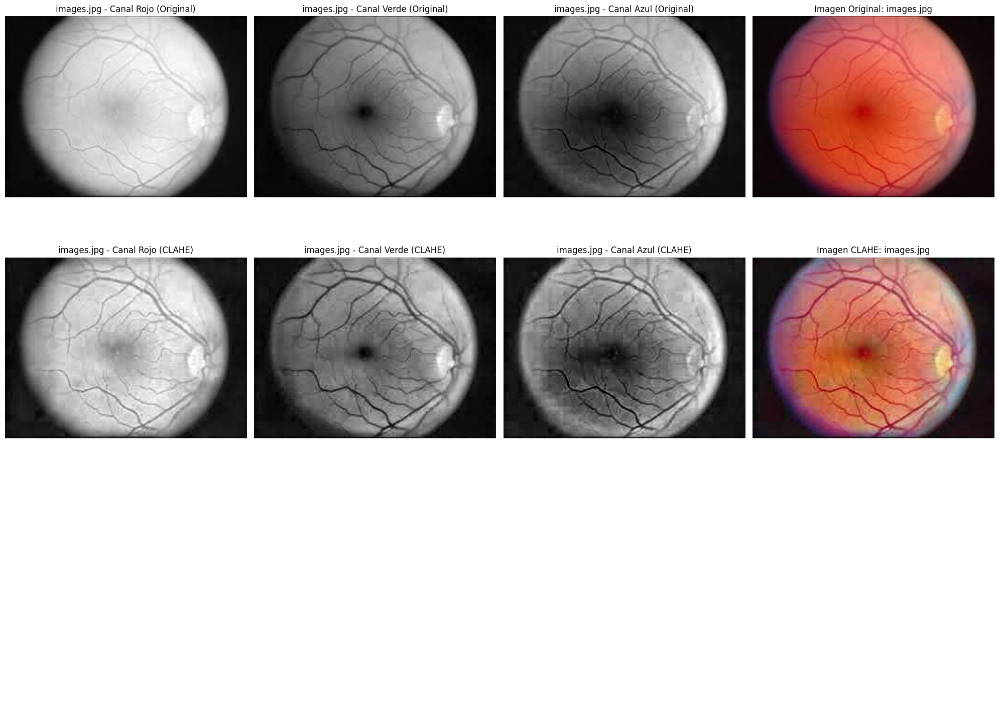

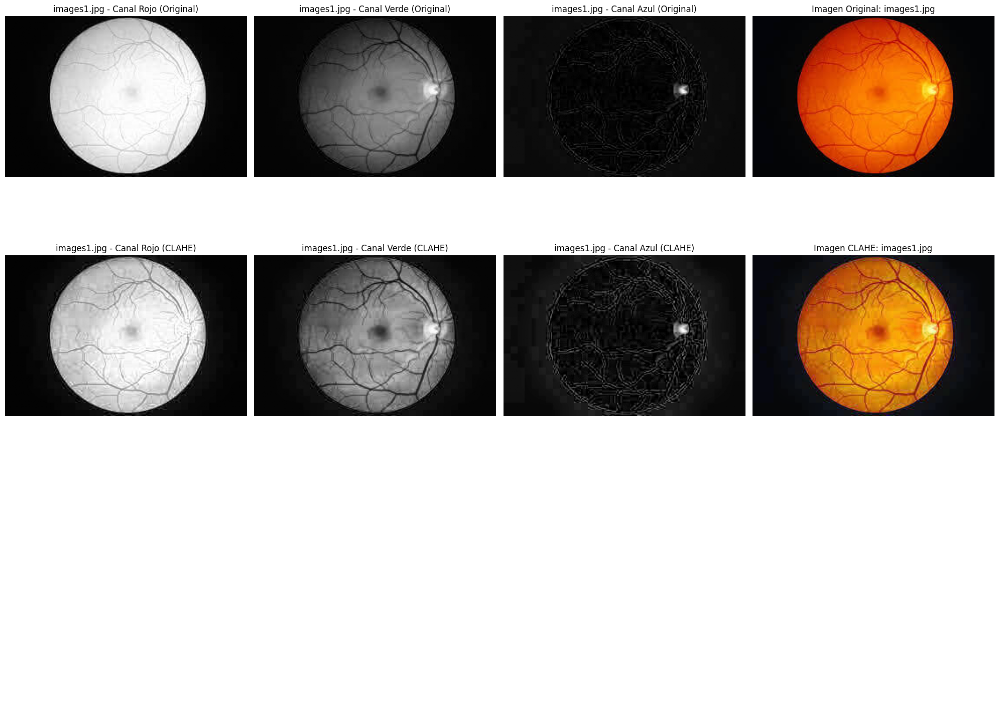

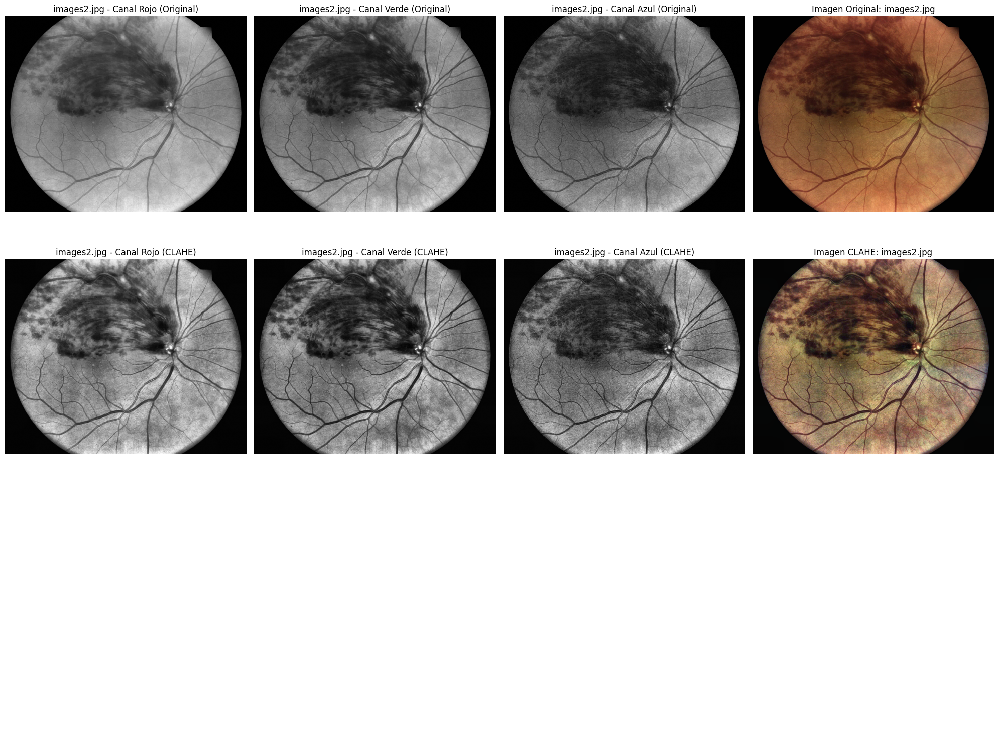

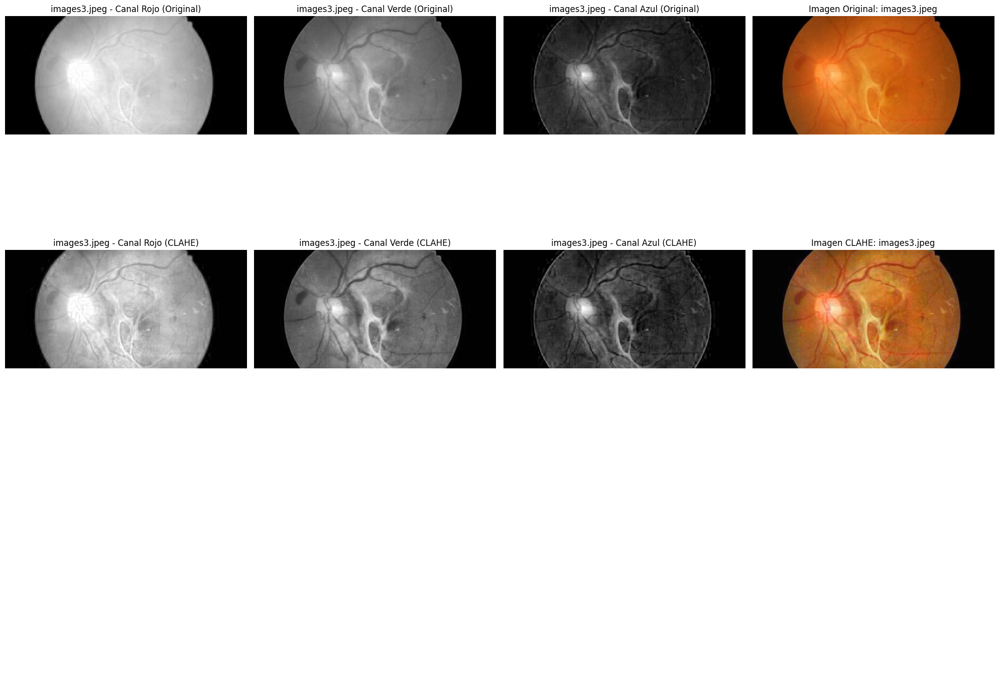

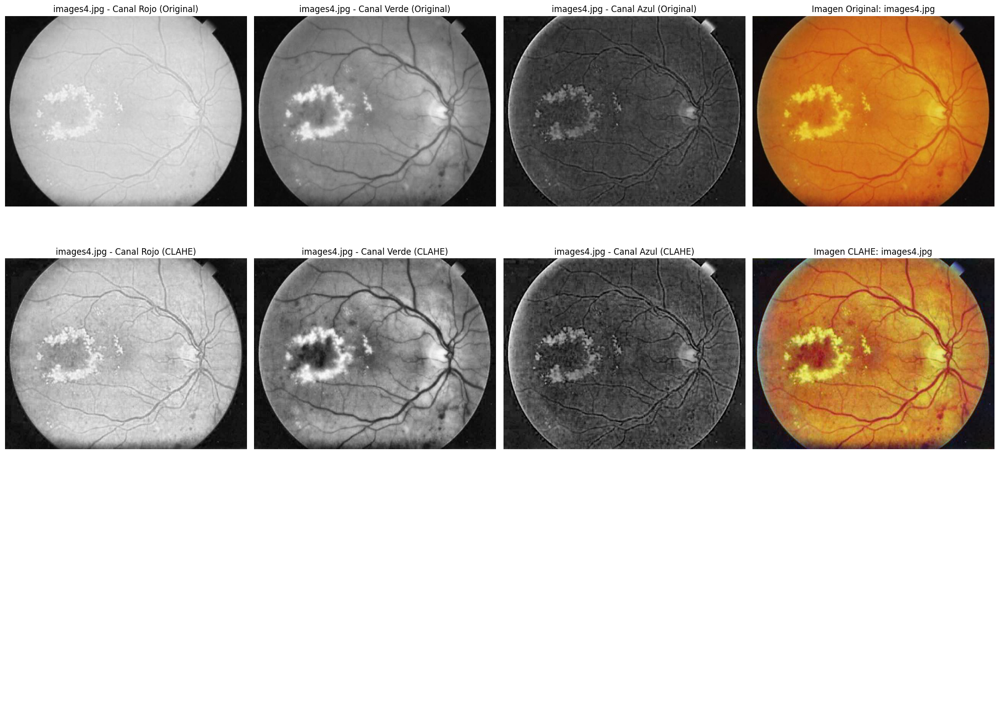

In [12]:
# Ruta de la carpeta de imágenes
carpeta_imagen = 'C:/Users/samir/OneDrive/Escritorio/Servicio/Bit-cora-de-laboratorio-Samira/tareas/mas'
# Crear un objeto CLAHE, crea herramienta que va a aplicar
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)) # cliplimit cuanto contraste se puede aumentar
 # TildeG le dice en cuantas regiones pequeñas va a dividir la imagen

# Iterar sobre todas las imágenes de la carpeta
for archivo_imagen in os.listdir(carpeta_imagen): # va leyendo imagen por imagen automáticamente de una lista de archivos
    if archivo_imagen.endswith(formatos_validos): # revisa si el archivo termina en una extensión válida
        ruta_imagen = os.path.join(carpeta_imagen, archivo_imagen) # crea la ruta a la imagen
        # Cargar la imagen en color
        imagen = cv2.imread(ruta_imagen) # abre la imagen y la carga en memoria como una matriz numérica
        # Separar los canales RGB, extrae cada canal de color por separado
        canal_rojo = imagen[:, :, 2]  # OpenCV carga en BGR, así que el rojo está en el índice 2
        canal_verde = imagen[:, :, 1]  # Verde en el índice 1
        canal_azul = imagen[:, :, 0]   # Azul en el índice 0
        # Aplicar CLAHE a cada canal, toma cada canal por separado y le mejora el contraste usando CLAHE
        canal_rojo_clahe = clahe.apply(canal_rojo)
        canal_verde_clahe = clahe.apply(canal_verde)
        canal_azul_clahe = clahe.apply(canal_azul)
        
        
        # Combinar los canales CLAHE
        clahe_imagen = cv2.merge((canal_azul_clahe, canal_verde_clahe, canal_rojo_clahe))  # OpenCV usa BGR
        # después de mejorar cada canal por separado, los vuelve a unir para reconstruir la imagen completa

        # Crear un gráfico para mostrar los canales y las imágenes
        fig, axs = plt.subplots(3, 4, figsize=(20, 15))

        # Canales originales en escala de grises
        axs[0, 0].imshow(canal_rojo, cmap='gray')
        axs[0, 0].set_title(f"{archivo_imagen} - Canal Rojo (Original)")
        axs[0, 0].axis('off')

        axs[0, 1].imshow(canal_verde, cmap='gray')
        axs[0, 1].set_title(f"{archivo_imagen} - Canal Verde (Original)")
        axs[0, 1].axis('off')

        axs[0, 2].imshow(canal_azul, cmap='gray')
        axs[0, 2].set_title(f"{archivo_imagen} - Canal Azul (Original)")
        axs[0, 2].axis('off')

        # Imagen original
        axs[0, 3].imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
        axs[0, 3].set_title(f'Imagen Original: {archivo_imagen}')
        axs[0, 3].axis('off')

        # Canales CLAHE en escala de grises
        axs[1, 0].imshow(canal_rojo_clahe, cmap='gray')
        axs[1, 0].set_title(f"{archivo_imagen} - Canal Rojo (CLAHE)")
        axs[1, 0].axis('off')

        axs[1, 1].imshow(canal_verde_clahe, cmap='gray')
        axs[1, 1].set_title(f"{archivo_imagen} - Canal Verde (CLAHE)")
        axs[1, 1].axis('off')

        axs[1, 2].imshow(canal_azul_clahe, cmap='gray')
        axs[1, 2].set_title(f"{archivo_imagen} - Canal Azul (CLAHE)")
        axs[1, 2].axis('off')

        # Imagen combinada con CLAHE, muestra la imagen final reconstruida, ya con CLAHE aplicado a sus tres canales
        axs[1, 3].imshow(cv2.cvtColor(clahe_imagen, cv2.COLOR_BGR2RGB))
        axs[1, 3].set_title(f'Imagen CLAHE: {archivo_imagen}')
        axs[1, 3].axis('off')

        # Espacios en blanco para la última fila (se puede modificar para más visualizaciones)
        for i in range(4):
            axs[2, i].axis('off')
            # apaga los 4 espacios de la tercera fila, se puede usar para histograma, canal verde separado, etc. 

        # Mostrar el gráfico
        plt.tight_layout() # ajusta automáticamente los espacios
        plt.show()